# QuKerNet微调与季度股票预测：证据核验

本 Notebook 读取已保存的公开汇总，不登录天衍、不读取实验室原始数据、不启动云任务。

**当前快照有真实的经典基线结果，尚无完整云端效果结果。**这里复核计划与已有证据，不把空缺量子结果填成0。2022—2024是开发期回放，2025继续封存；D0原始价格标签不支持策略净收益或未来盈利结论。

学习目标：区分KTA、验证选核和季度预测；核对日期等权指标；解释同配置初值对照；检查预算和证据边界。

In [1]:
from pathlib import Path
import csv, hashlib, json, math
from IPython.display import Markdown, Image, display

relative = Path('reports/qukernet_cloud_v2/efficacy_classical_snapshot_20261114.json')
root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / relative).is_file()), None)
if root is None:
    raise FileNotFoundError('请在课程仓库或其子目录打开此 Notebook；需要随仓库提供的公开汇总。')
folder = root / relative.parent
evidence = json.loads((root / relative).read_text(encoding='utf-8'))
csv_file = folder / 'efficacy_classical_aggregates_20261114.csv'
assert hashlib.sha256(csv_file.read_bytes()).hexdigest() == evidence['provenance']['csv_sha256']
with csv_file.open(encoding='utf-8') as f:
    rows = list(csv.DictReader(f))
assert len(rows) == 30
assert evidence['quantum_results'] == []
assert evidence['execution']['cloud_submissions'] == 0
print('已读取30条经典汇总（3季度 × 5模型 × 验证/季度两个区间）。')
print('量子效果结果：此快照尚无完整结果。')

已读取30条经典汇总（3季度 × 5模型 × 验证/季度两个区间）。
量子效果结果：此快照尚无完整结果。


## 1. 先看后续季度，再解释选择过程

每组只有16个训练样本和16个验证样本，40项特征及缩放只用训练期确定。RBF在验证区选择γ，不能用季度评价区选择γ。下表的 `O` 为后续季度开发回放；每季度11个评价日期。固定上涨与固定下跌均是预设基线。

In [2]:
quarters = ['2022Q1', '2023Q1', '2024Q1']
models = ['majority', 'always0', 'always1', 'linear', 'rbf']
names = {'majority':'训练多数类', 'always0':'固定跌', 'always1':'固定涨', 'linear':'线性 SVC', 'rbf':'RBF SVC'}
def result(quarter, model, split='O'):
    return next(r for r in rows if r['quarter']==quarter and r['model']==model and r['split']==split)
lines = ['|季度|模型|日期数|准确率（日期等权）|平衡准确率|AUC|', '|---|---|---:|---:|---:|---:|']
for q in quarters:
    for model in models:
        r=result(q,model)
        lines.append(f"|{q}|{names[model]}|{r['evaluation_dates']}|{float(r['date_equal_accuracy']):.2%}|{float(r['balanced_accuracy']):.2%}|{float(r['roc_auc']):.3f}|")
display(Markdown('\n'.join(lines)))

|季度|模型|日期数|准确率（日期等权）|平衡准确率|AUC|
|---|---|---:|---:|---:|---:|
|2022Q1|训练多数类|11|58.64%|50.00%|0.500|
|2022Q1|固定跌|11|58.64%|50.00%|0.500|
|2022Q1|固定涨|11|41.36%|50.00%|0.500|
|2022Q1|线性 SVC|11|53.18%|51.82%|0.530|
|2022Q1|RBF SVC|11|58.64%|50.00%|0.571|
|2023Q1|训练多数类|11|46.41%|50.00%|0.500|
|2023Q1|固定跌|11|46.41%|50.00%|0.500|
|2023Q1|固定涨|11|53.59%|50.00%|0.500|
|2023Q1|线性 SVC|11|45.45%|47.38%|0.462|
|2023Q1|RBF SVC|11|47.37%|49.51%|0.444|
|2024Q1|训练多数类|11|42.27%|50.00%|0.500|
|2024Q1|固定跌|11|42.27%|50.00%|0.500|
|2024Q1|固定涨|11|57.73%|50.00%|0.500|
|2024Q1|线性 SVC|11|41.82%|49.03%|0.518|
|2024Q1|RBF SVC|11|42.27%|50.00%|0.499|

## 2. 准确率的权重为什么要写清楚

\[
\mathrm{Acc}=\frac{1}{D}\sum_{d=1}^{D}\frac{1}{n_d}\sum_{i\in d}\mathbf1(\hat y_i=y_i).
\]

每个日期总权重相同；平衡准确率用同一权重先构造混淆矩阵，再对两类召回率取平均。不能把209或220条股票记录视为相互独立的市场样本。图只显示真实经典汇总，无量子占位曲线。

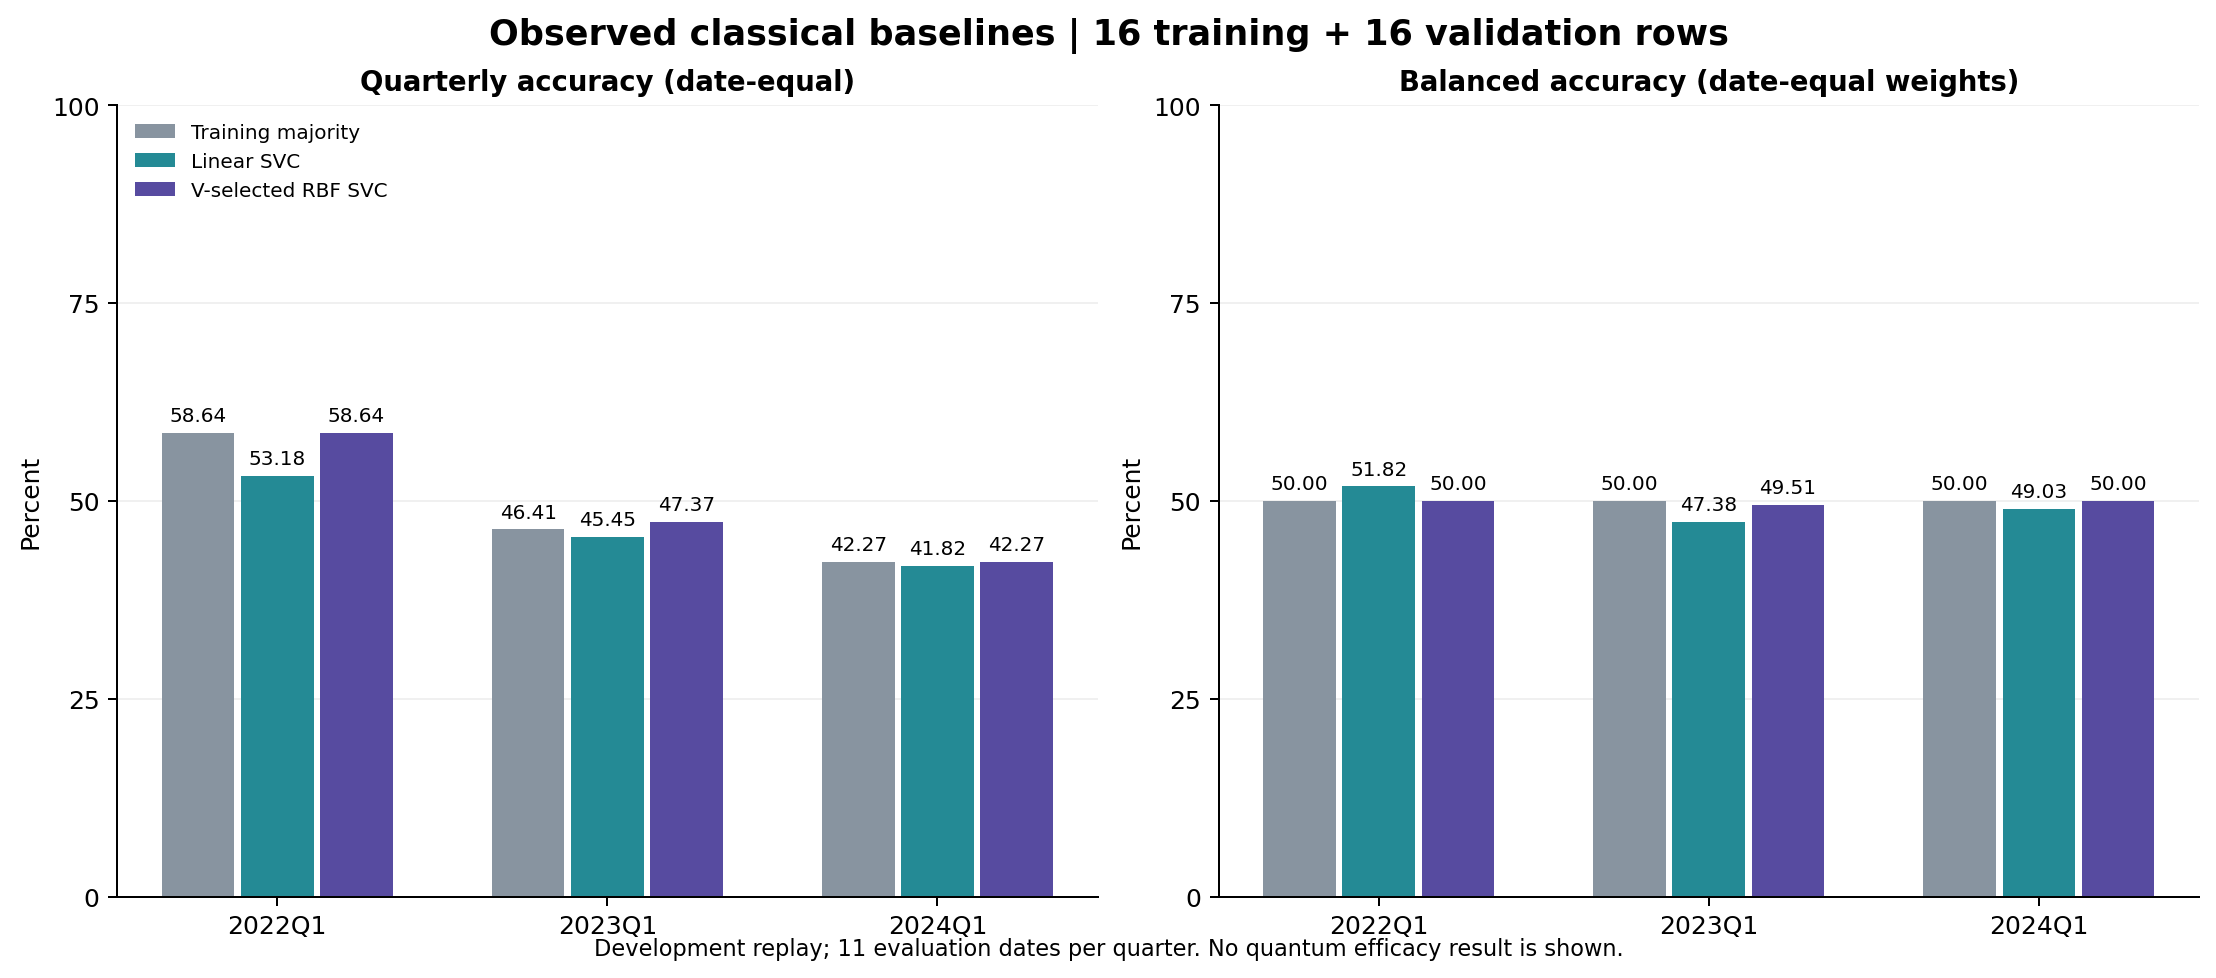

2022Q1、2024Q1的RBF硬分类均为跌；AUC使用连续决策分数，数值可不同于0.5。


In [3]:
display(Image(filename=str(folder/'figures/efficacy_classical_baselines_20261114.png')))
for q in ['2022Q1','2024Q1']:
    r=result(q,'rbf')
    assert math.isclose(float(r['recall_class_0']),1.0)
    assert math.isclose(float(r['recall_class_1']),0.0)
    assert math.isclose(float(r['balanced_accuracy']),0.5)
print('2022Q1、2024Q1的RBF硬分类均为跌；AUC使用连续决策分数，数值可不同于0.5。')

## 3. 配对差值与不确定性

已保存的RBF−多数类区间来自季度内相邻日期的非循环移动块重采样；主块长2，敏感性块长1、3，各10,000次，季度等权。下面可以用公开季度汇总复算点估计并核对保存的区间。

公开汇总没有逐日期配对预测，因而不能从本 Notebook 重新生成该重采样分布。完整方法在课程的 `efficacy_analysis.py`；私有配对记录另存。区间是探索性的，不包含重选模型、测量重采样或搜索种子变化的不确定性，未作多重比较校正。

In [4]:
deltas=[float(result(q,'rbf')['date_equal_accuracy'])-float(result(q,'majority')['date_equal_accuracy']) for q in quarters]
point=sum(deltas)/len(deltas)
saved=evidence['classical_rbf_minus_majority_bootstrap']
assert saved['coverage']['complete']
assert math.isclose(point,saved['blocks']['2']['delta_date_equal_accuracy']['estimate'],abs_tol=1e-12)
print(f'三季度等权RBF−多数类差：{100*point:+.2f} 个百分点')
for length in ['2','1','3']:
    stat=saved['blocks'][length]['delta_date_equal_accuracy']
    lo,hi=stat['ci95']
    print(f'块长{length}：探索性95%区间 [{100*lo:+.2f}, {100*hi:+.2f}] 个百分点')
print('主区间跨零：此经典对照尚不能支持可靠优势。')

三季度等权RBF−多数类差：+0.32 个百分点
块长2：探索性95%区间 [-1.59, +2.87] 个百分点
块长1：探索性95%区间 [-1.91, +2.55] 个百分点
块长3：探索性95%区间 [-1.12, +2.71] 个百分点
主区间跨零：此经典对照尚不能支持可靠优势。


## 4. 微调、搜索与预测是三个问题

分类训练KTA为 $\langle K,Y\rangle_F/(\|K\|_F\|Y\|_F)$，同类 $Y_{ij}=1$、异类 $Y_{ij}=-1$。它不是准确率。

计划中的三种配对分别为：

1. 获选QuKerNet终点−同配置、同门替换位置的初值θ₀；两者分别重新拟合SVC。
2. 获选QuKerNet终点−匹配量子评价配额的随机搜索终点。
3. 获选QuKerNet终点−验证选定的RBF SVC。

所有配置均保存初值与终点的训练、验证评价，**只以终点验证表现选择最终配置**，随后才评估该配置终点与自身θ₀的季度结果。第1项是获选配置相对自身初值的条件性变化；不代表全配置平均效应或最优未微调方法的比较。

所需证据包括全部配置终点、验证选择记录、同配置重载一致性、季度配对记录、随机搜索对应结果以及账本。KTA提高、季度未改善时，只能说训练代理目标提高。

In [5]:
plan=evidence['authorized_plan']
budget=[('2022Q1',31488,1612),('2023Q1',30784,1580),('2024Q1',31488,1612)]
circuits=sum(x[1] for x in budget)
shots=circuits*plan['shots_per_probability_circuit']
batches=sum(x[2] for x in budget)
assert (circuits,shots,batches)==(93760,48005120,4804)
assert circuits==plan['circuits_upper'] and shots==plan['requested_shots_upper']
print(f'授权上限：6组，{circuits:,}条概率线路，{shots:,}请求shots，{batches:,}批。')
print('上限不是已执行次数；每次概率计算的移位线路与失败尝试都须计费。')
print('批次不能跨所有矩阵/操作任意拼接，因此不是简单的总线路数÷20。')
print('首次主实验预约启动72小时；每批至多20条，300秒内未完成核验即停止新增与自动轮询。')

授权上限：6组，93,760条概率线路，48,005,120请求shots，4,804批。
上限不是已执行次数；每次概率计算的移位线路与失败尝试都须计费。
批次不能跨所有矩阵/操作任意拼接，因此不是简单的总线路数÷20。
首次主实验预约启动72小时；每批至多20条，300秒内未完成核验即停止新增与自动轮询。


## 5. 练习与验收

- 解释2024Q1训练14跌、2涨时，KTA、准确率和平衡准确率可能怎样分离。
- 说明如果微调终点验证最好但季度变差，结论应如何表述。
- 说明为什么缺失季度不能填0，以及部分完成时应如何报告覆盖范围。
- 在拿到完整云结果后，按预定的三个配对计算差值；结果不改善也必须保留。

本 Notebook 的通过条件是：公开CSV哈希匹配、30条汇总完整、点估计与已保存重采样结果一致、预算一致；它不对尚未取得的量子效果给出通过认证。

[执行说明与证据边界](../../reports/qukernet_cloud_v2/微调与预测效果验证_执行说明_20261114.md) · [搜索实现](../../experiments/qukernet_finance/cloud_v2/search.py) · [评价实现](../../experiments/qukernet_finance/cloud_v2/efficacy_analysis.py)

本研究仅作开发回放与课程方法验证，不据此作未来盈利或量子优势判断。